# OULAD At-Risk Prediction: Focused EDA

This notebook performs focused EDA for the processed OULAD dataset.

The goal is not to describe every column. The goal is to make preprocessing decisions for the next notebook.

The main questions are:

- Is the target class balanced?
- Are there missing values that need handling?
- Do academic performance, engagement, and registration timing differ between safe and at-risk students?
- Which categorical features may be useful in the expert system and ML models?
- Which columns need encoding, scaling, or cleanup?


## Setup

Import the libraries and set display options.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 140)


## Load Data

Load the processed OULAD CSV generated by the R preprocessing script.


In [2]:
DATA_PATH = Path("data/oulad_processed.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not find data/oulad_processed.csv. "
        "Run preprocess_oulad.R first and save the output in the data folder."
    )

df = pd.read_csv(DATA_PATH)

print(f"Loaded file: {DATA_PATH}")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")

df.head()


Loaded file: data\oulad_processed.csv
Shape: 1452 rows, 11 columns


,date_registration,gender,region,highest_education,imd_band,age_band,studied_credits,disability,average_CA_score,total_clicks,final_result
0,-92,Female,Scotland,HE Qualification,40-50%,35-55,120,N,78.558140,474,Pass
1,-29,Female,West Midlands Region,A Level or Equivalent,20-30%,0-35,60,Y,87.255814,237,Pass
2,-29,Female,North Western Region,A Level or Equivalent,0-10%,35-55,60,N,76.116279,1929,Pass
3,-24,Female,Scotland,A Level or Equivalent,60-70%,35-55,60,N,83.488372,539,Distinction
4,-32,Female,South Region,A Level or Equivalent,90-100%,35-55,60,N,84.883721,238,Pass


## Basic Structure

Check column types, missing values, unique values, and duplicate rows.

This tells us what cleaning is needed before modeling.


In [3]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values(["missing_count", "unique_values"], ascending=[False, True])

display(summary)

duplicate_rows = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_rows}")


,dtype,missing_count,missing_percent,unique_values
imd_band,object,8,0.55,10
gender,object,0,0.00,2
disability,object,0,0.00,2
age_band,object,0,0.00,3
final_result,object,0,0.00,4
highest_education,object,0,0.00,5
studied_credits,int64,0,0.00,11
region,object,0,0.00,13
date_registration,int64,0,0.00,156
total_clicks,int64,0,0.00,715


Duplicate rows: 0


## Create Binary Target

Convert `final_result` into the target used for at-risk prediction.

- `Fail` and `Withdrawn` are treated as **At Risk**
- `Pass` and `Distinction` are treated as **Not At Risk**


In [4]:
target_map = {
    "Fail": 1,
    "Withdrawn": 1,
    "Pass": 0,
    "Distinction": 0
}

unexpected_results = sorted(set(df["final_result"].dropna()) - set(target_map))

if unexpected_results:
    raise ValueError(f"Unexpected final_result values found: {unexpected_results}")

eda_df = df.copy()
eda_df["at_risk"] = eda_df["final_result"].map(target_map)

class_names = {
    0: "Not At Risk",
    1: "At Risk"
}

eda_df[["final_result", "at_risk"]].head()


,final_result,at_risk
0,Pass,0
1,Pass,0
2,Pass,0
3,Distinction,0
4,Pass,0


## Target Distribution

Check whether the prediction problem is imbalanced.

This matters because if one class is much larger, accuracy alone will not be enough for evaluation.


,count,percent
at_risk,,
Not At Risk,959,66.05
At Risk,493,33.95


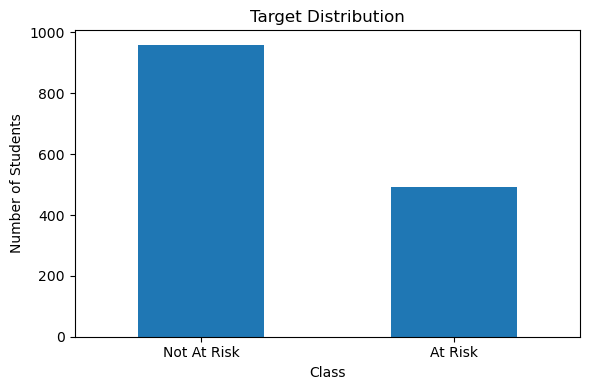

In [5]:
target_distribution = (
    eda_df["at_risk"]
    .map(class_names)
    .value_counts()
    .to_frame("count")
)

target_distribution["percent"] = (
    target_distribution["count"] / len(eda_df) * 100
).round(2)

display(target_distribution)

plt.figure(figsize=(6, 4))
target_distribution["count"].plot(kind="bar")
plt.title("Target Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Input Feature Groups

The plots below are grouped by feature meaning, not by data type.

- Registration: `date_registration`
- Academic performance: `average_CA_score`
- Engagement: `total_clicks`
- Demographics/background: `gender`, `region`, `highest_education`, `imd_band`, `age_band`, `studied_credits`, `disability`

`final_result` is not plotted as an input feature because it is only used to create the target.


In [6]:
feature_groups = {
    "Registration": [
        "date_registration"
    ],
    "Academic Performance": [
        "average_CA_score"
    ],
    "Engagement": [
        "total_clicks"
    ],
    "Demographics / Background": [
        "gender",
        "region",
        "highest_education",
        "imd_band",
        "age_band",
        "studied_credits",
        "disability"
    ]
}

input_features = [
    feature
    for features in feature_groups.values()
    for feature in features
]

missing_features = [
    feature
    for feature in input_features
    if feature not in eda_df.columns
]

if missing_features:
    raise ValueError(f"Missing expected input features: {missing_features}")

numeric_features = eda_df[input_features].select_dtypes(include="number").columns.tolist()
categorical_features = eda_df[input_features].select_dtypes(exclude="number").columns.tolist()

print("Input feature groups:")
for group_name, features in feature_groups.items():
    print(f"{group_name}: {', '.join(features)}")


Input feature groups:
Registration: date_registration
Academic Performance: average_CA_score
Engagement: total_clicks
Demographics / Background: gender, region, highest_education, imd_band, age_band, studied_credits, disability


## Plot Helpers

These helper functions plot the target distribution for one feature at a time.

For numeric features, values are grouped into quantile bins.  
For categorical features, each category is shown directly.

Each bar is labeled with its exact count.


In [7]:
def add_bar_labels(ax):
    """Add count labels above each bar."""

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.0f",
            padding=3
        )


def plot_target_distribution_by_categorical_feature(data, feature):
    """Plot target counts for each category of a categorical feature."""

    plot_data = data.copy()
    # Keep missing categorical values visible as their own category.
    # This is especially relevant for imd_band, which has a few missing values.
    plot_data[feature] = plot_data[feature].fillna("Unknown")
    plot_data["risk_label"] = plot_data["at_risk"].map(class_names)

    counts = pd.crosstab(
        plot_data[feature],
        plot_data["risk_label"]
    )

    counts = counts.reindex(
        columns=["Not At Risk", "At Risk"],
        fill_value=0
    )

    ax = counts.plot(
        kind="bar",
        figsize=(10, 4)
    )

    add_bar_labels(ax)

    plt.title(f"Target Distribution by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Students")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


def plot_target_distribution_by_numeric_feature(data, feature, bins=4):
    """Plot target counts across quantile bins of a numeric feature."""

    plot_data = data.copy()
    plot_data["risk_label"] = plot_data["at_risk"].map(class_names)

    # qcut creates bins with roughly similar numbers of students.
    # duplicates='drop' prevents errors if repeated values reduce the number of possible bins.
    plot_data[f"{feature}_bin"] = pd.qcut(
        plot_data[feature],
        q=bins,
        duplicates="drop"
    )

    counts = pd.crosstab(
        plot_data[f"{feature}_bin"],
        plot_data["risk_label"]
    )

    counts = counts.reindex(
        columns=["Not At Risk", "At Risk"],
        fill_value=0
    )

    ax = counts.plot(
        kind="bar",
        figsize=(10, 4)
    )

    add_bar_labels(ax)

    plt.title(f"Target Distribution by {feature}")
    plt.xlabel(f"{feature} range")
    plt.ylabel("Number of Students")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


def plot_feature_group(data, group_name, features):
    """Plot all features in one feature group."""

    print(f"\n{group_name}")

    for feature in features:
        if feature in numeric_features:
            plot_target_distribution_by_numeric_feature(
                data=data,
                feature=feature,
                bins=4
            )
        else:
            plot_target_distribution_by_categorical_feature(
                data=data,
                feature=feature
            )


## Registration

Plot target distribution by registration timing.



Registration


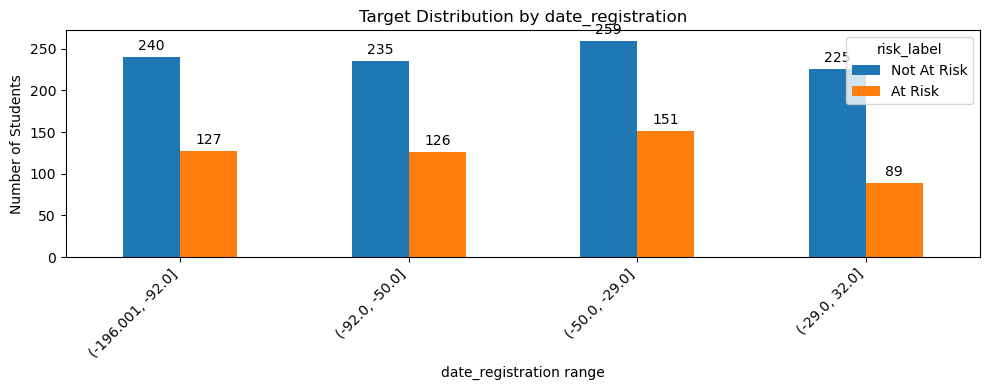

In [8]:
plot_feature_group(
    data=eda_df,
    group_name="Registration",
    features=feature_groups["Registration"]
)


## Academic Performance

Plot target distribution by early assessment performance.



Academic Performance


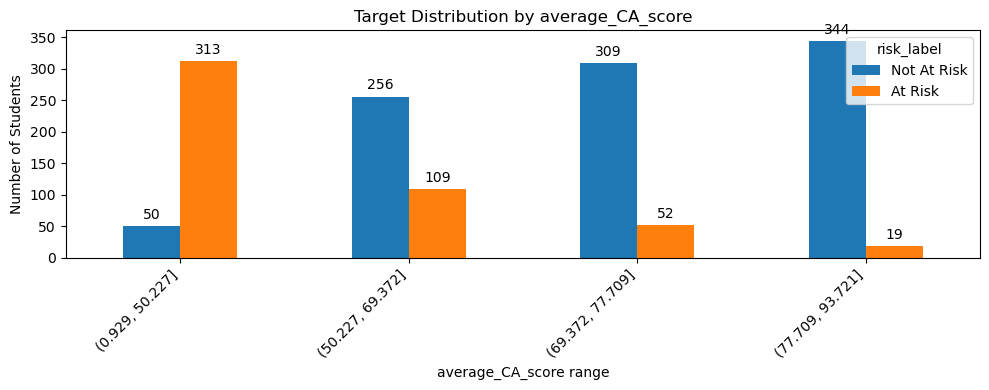

In [9]:
plot_feature_group(
    data=eda_df,
    group_name="Academic Performance",
    features=feature_groups["Academic Performance"]
)


## Engagement

Plot target distribution by total VLE clicks.



Engagement


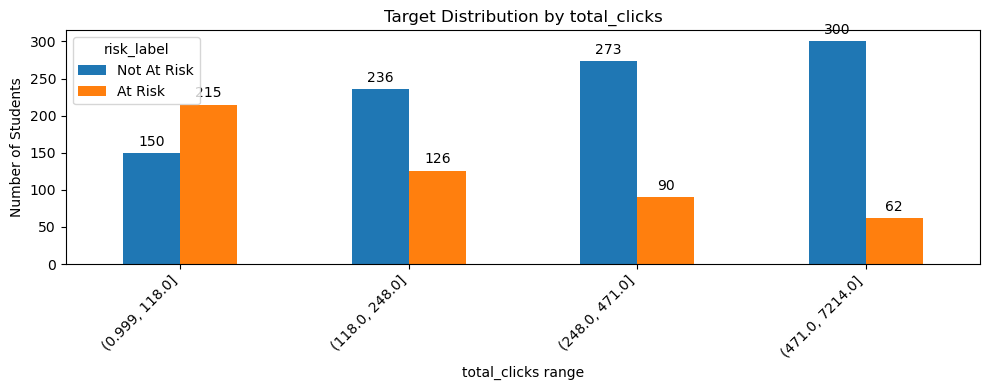

In [10]:
plot_feature_group(
    data=eda_df,
    group_name="Engagement",
    features=feature_groups["Engagement"]
)


## Demographics / Background

Plot target distribution by demographic and background features.



Demographics / Background


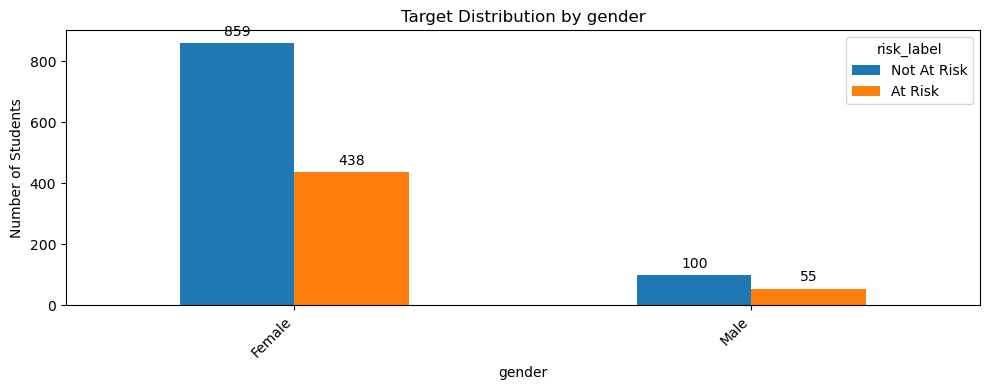

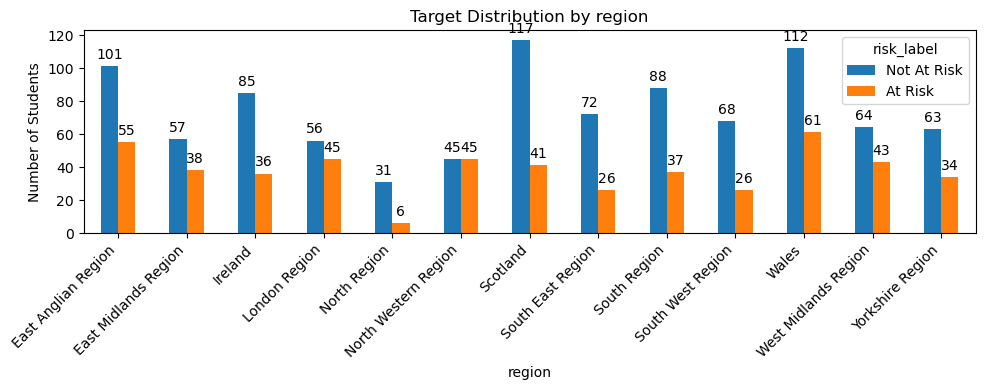

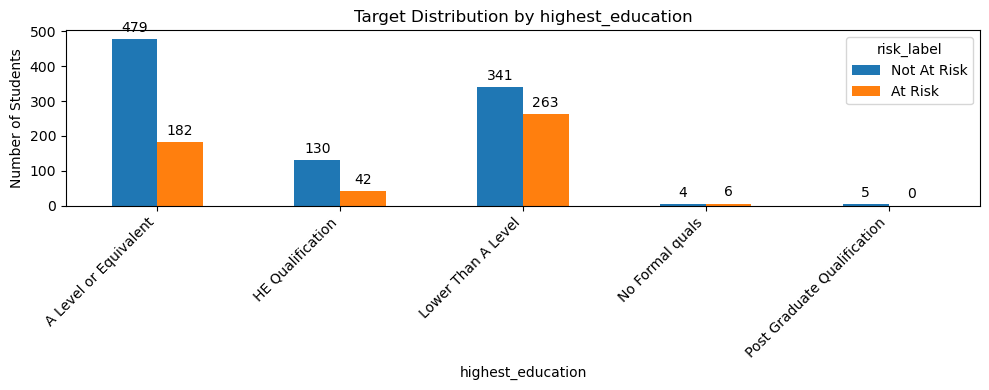

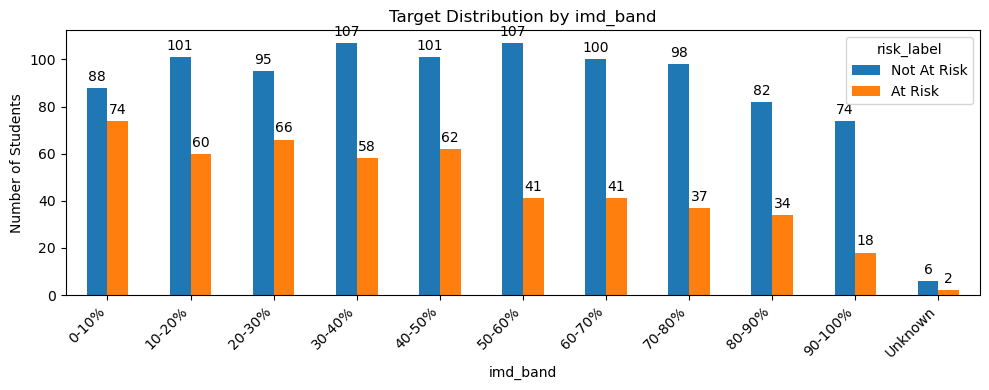

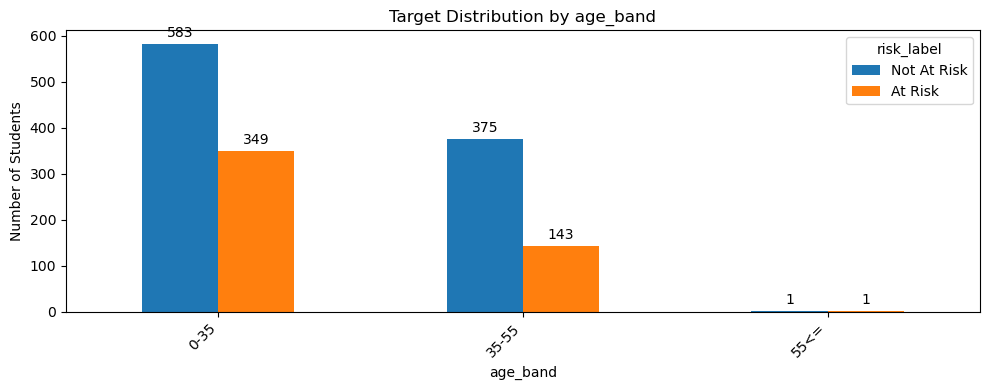

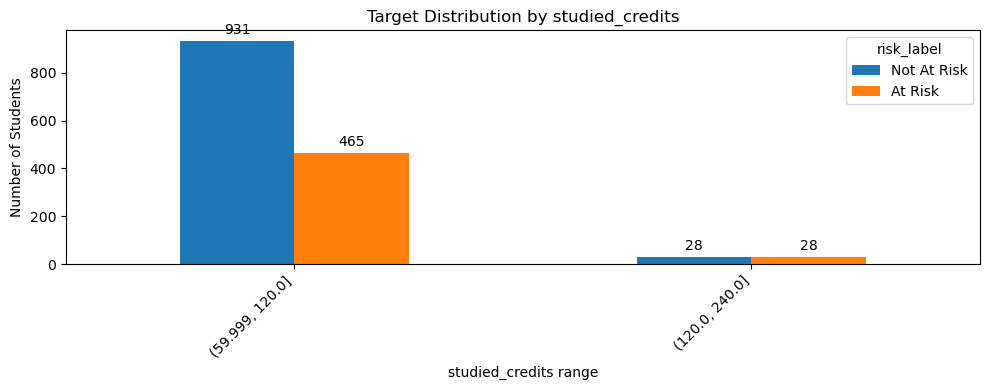

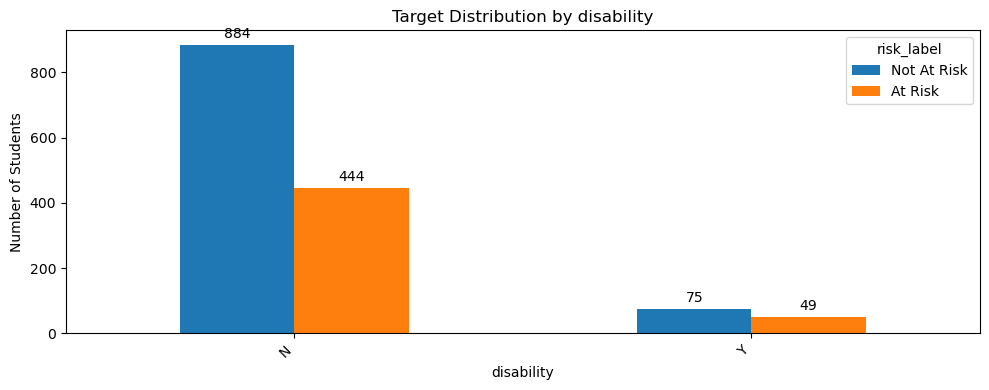

In [11]:
plot_feature_group(
    data=eda_df,
    group_name="Demographics / Background",
    features=feature_groups["Demographics / Background"]
)
